In [1]:
import numpy as np
import discretisedfield as df
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import os 
from scripts.scientific import apply
from matplotlib.colors import hsv_to_rgb
import matplotlib.patches as patches
import matplotlib as mpl
from scripts.read_field import file_to_array, read_dir, draw_field, animate_field 

mpl.rcParams.update(mpl.rcParamsDefault)
apply()


### Draw

In [28]:
new_name = './01-repulsion/skyrmion_system/drive-0'
# new_name = 'recorderd-skyrmion-creation,alpha=5'
data = read_dir(new_name, delete_files=False, new_name=None, scaling=1e5)


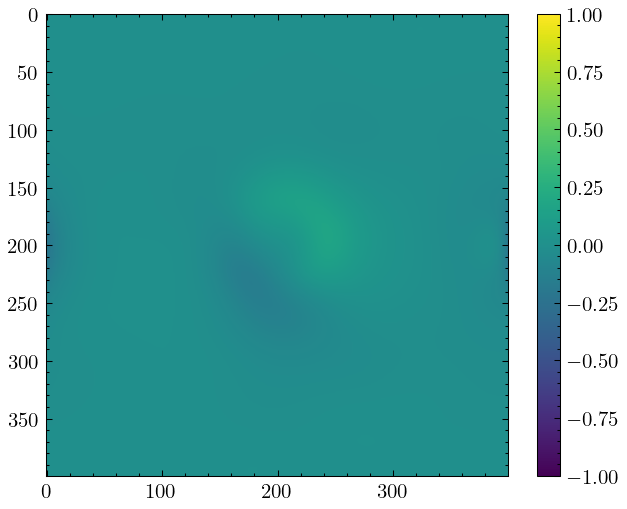

In [30]:
plt.imshow(data[1,:,:,2] - data[0,:,:,2], vmin=-1, vmax=1)
plt.colorbar()

In [11]:
# data = np.vstack([
#     # read_dir('drive-35', delete_files=False, new_name='drive-35')[::2],
#     read_dir('drive-38-beta=-2-roation-start', delete_files=False, new_name='drive-38-beta=-2-roation-start'),
#     read_dir('drive-39', delete_files=False, new_name='drive-39'),
#     read_dir('drive-40-beta=-2-rotation-end', delete_files=False, new_name='drive-40-beta=-2-rotation-end'),
#     read_dir('drive-47-beta=-2-rotation-continue', delete_files=False, new_name='drive-47-beta=-2-rotation-continue'),
#     read_dir('drive-48-beta=-2-rotation-continue', delete_files=False, new_name='drive-48-beta=-2-rotation-continue'),
# ])[::5]


# new_name = 'drive-48-beta=-2-rotation-continue'
data = np.vstack([
    # read_dir('drive-35', delete_files=False, new_name='drive-35')[::2],
    read_dir('drive-52', delete_files=False, new_name='drive-52'),
    read_dir('drive-53', delete_files=False, new_name='drive-53'),
])


new_name = 'drive-53'

FileNotFoundError: [Errno 2] No such file or directory: './skyrmion_system/drive-52'

In [27]:
animate_field(data, new_name, mode='chirality', cutoff=50)

In [140]:
def patch(ax):
    c = patches.Circle((0,0), np.sqrt((3 / 0.5) ** (2/3) - 1), facecolor="none", edgecolor='k', linestyle='--')
    ax.add_patch(c)
animate_field(data, new_name, mode='chirality', cutoff=1, patch=patch)

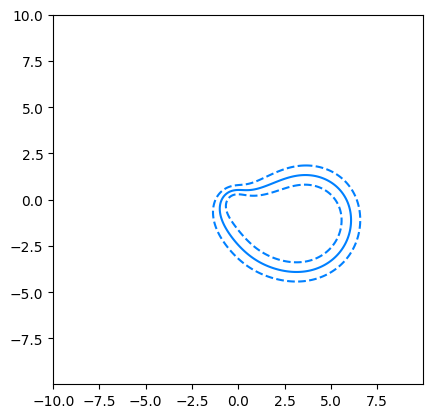

In [81]:
length = data.shape[-2]
center = length / 2 * 0.025
X,Y = np.meshgrid(np.arange(0, length) * 0.025 - center, center-np.arange(0, length) * 0.025)
fig, ax =plt.subplots()
ax.set_aspect(1)
i = 10
plt.contour(
    X, Y, data[i,:,:,2], levels=[0], colors=(0,0.5,1)
)
plt.contour(
    X, Y, data[i,:,:,2], levels=[-0.5,0.5], colors=(0,0.5,1), linestyles='--'
)

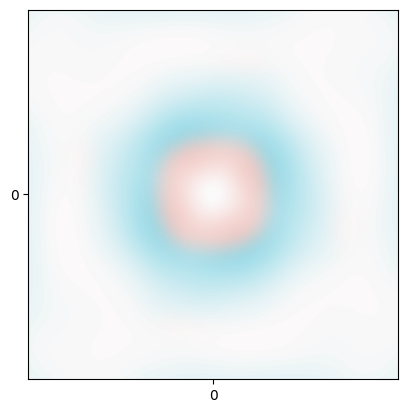

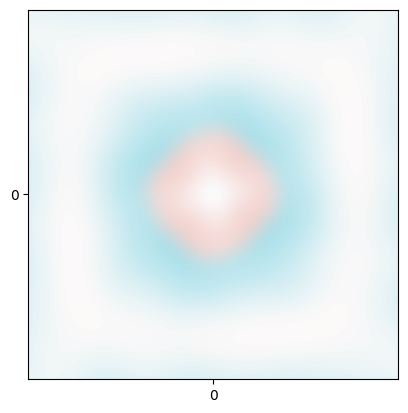

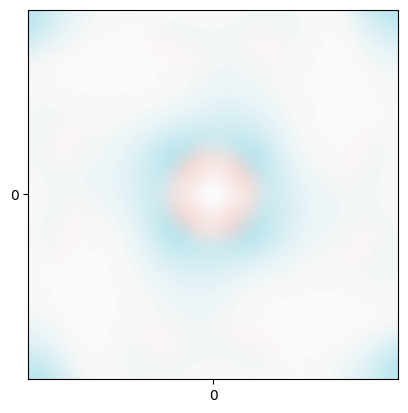

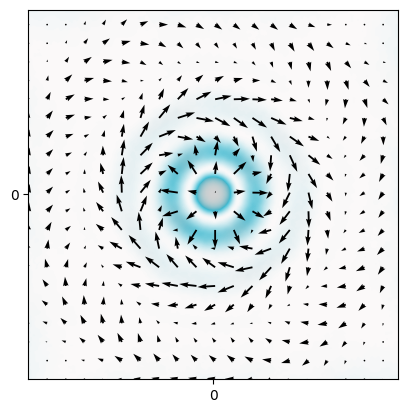

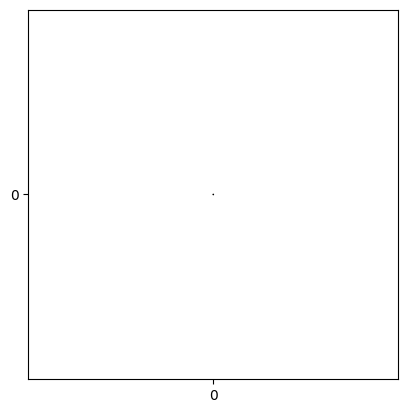

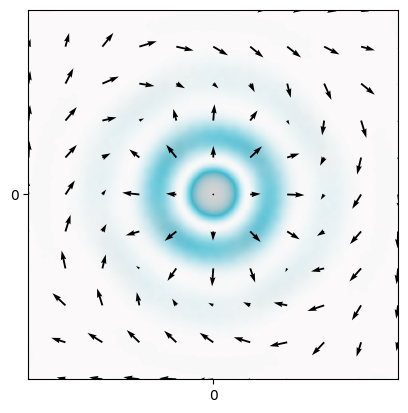

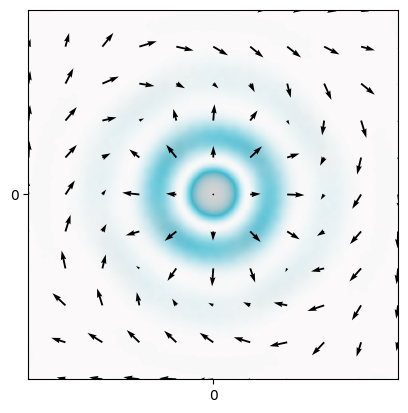

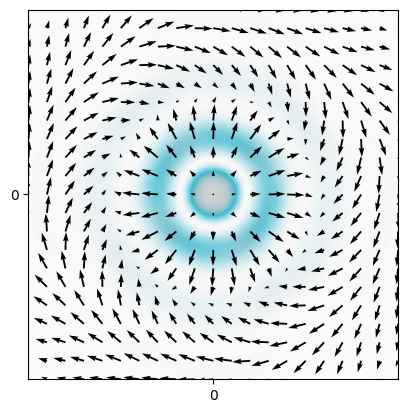

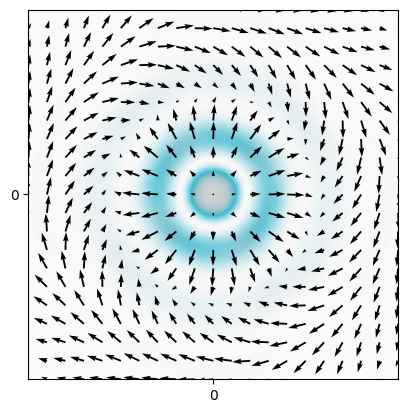

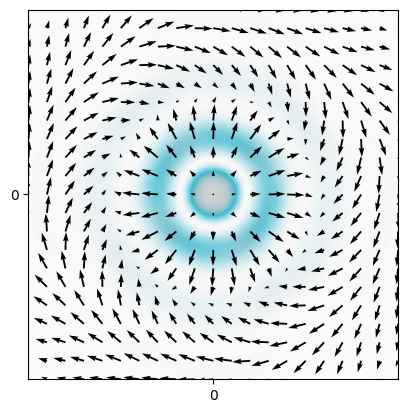

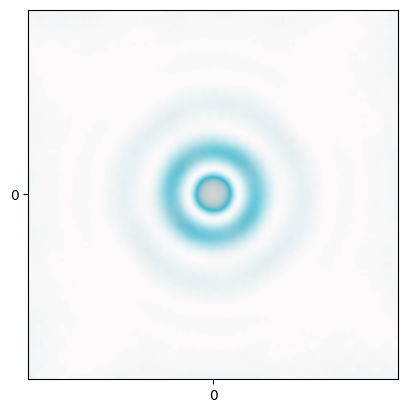

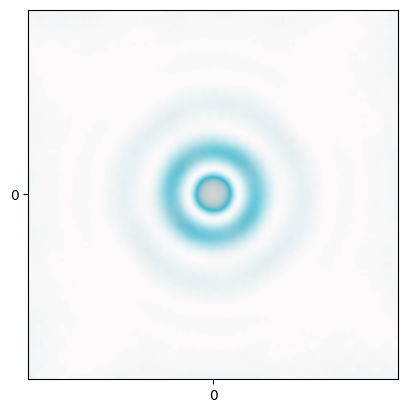

In [89]:
fig, ax = plt.subplots()
draw_field(ax, data[-1], 'chirality', cutoff=1)
plt.show()
# fig.savefig('./shapes/negative.png', dpi=300)


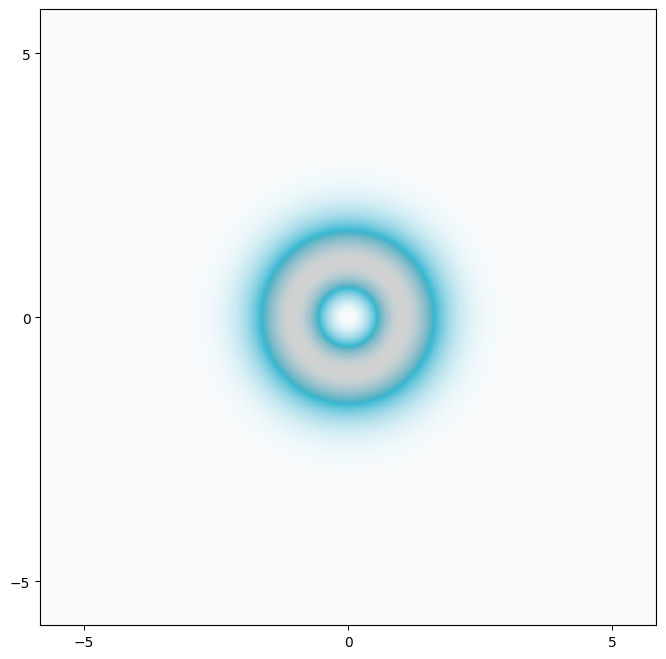

In [17]:
from scripts.ansatz import DomainWallAnsatz as dwa 

x, y = np.meshgrid(np.linspace(-10, 10, 600), np.linspace(-10, 10, 600))
phi = np.atan2(y,x)
r = np.sqrt(x **2 + y ** 2)
theta = dwa.theta(r, 1.5, 1) * 2
m = np.stack([np.sin(theta) * np.cos(phi), np.sin(theta) * np.sin(phi), np.cos(theta)]).transpose(1,2,0)
antichirality = np.gradient(m[:,:,2], axis=1) * m[:,:,1] - np.gradient(m[:,:,2], axis=0)

fig, ax = plt.subplots(1,1, figsize=(8,8))
draw_field(ax, m, 'chirality')
plt.show()
# charge = np.sum(m * np.linalg.cross(np.gradient(m, axis=0), np.gradient(m, axis=1)), axis=2) * (1 - m[:,:,-1] ** 2)

# plt.imshow(gaussian_filter((np.sign(charge) + 1) / 2, sigma=10), cmap=cmap2)
# plt.imshow(gaussian_filter((np.sign(charge) + 1) / 2, sigma=10), cmap=cmap)

In [187]:
plt.plot(data[9,200,:,2])
plt.ylim([-1,1])

IndexError: index 9 is out of bounds for axis 0 with size 2

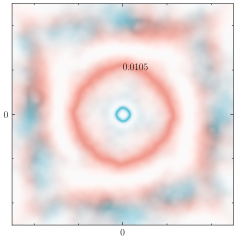

In [178]:
series = [
    'drive-2',
    'drive-3',
    'drive-4',
]

data = read_dir(series[0], delete_files=False, new_name=series[0])

for s in series[1:]:
    data = np.vstack((data, read_dir(s, delete_files=False, new_name=s)))
animate_field(data, series[-1], mode='chirality', cutoff=50)


In [168]:
file_to_array("./skyrmion_system/drive-37/skyrmion_system.odt")

ValueError: Reading file with extension .odt not supported.

MovieWriter ffmpeg unavailable; using Pillow instead.


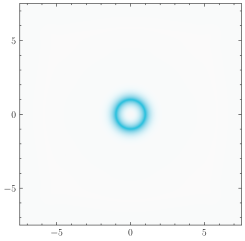

In [17]:
new_data = np.vstack([data[:1]] * 7 +[data])
animate_field(new_data, new_name, mode='chirality', cutoff=100)

In [117]:
%matplotlib widget

In [118]:
from scripts.scientific import apply
plt.rcdefaults()
apply()
# plt.rcParams["axes.edgecolor"] = 'black'
# plt.rcParams["axes.linewidth"]  = 0.5
# plt.style.use(['science', 'light'])
# plt.rcParams['figure.figsize'] = (5,4)
# plt.rcParams['figure.dpi'] = 150
# plt.rcParams['savefig.dpi'] = 150
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

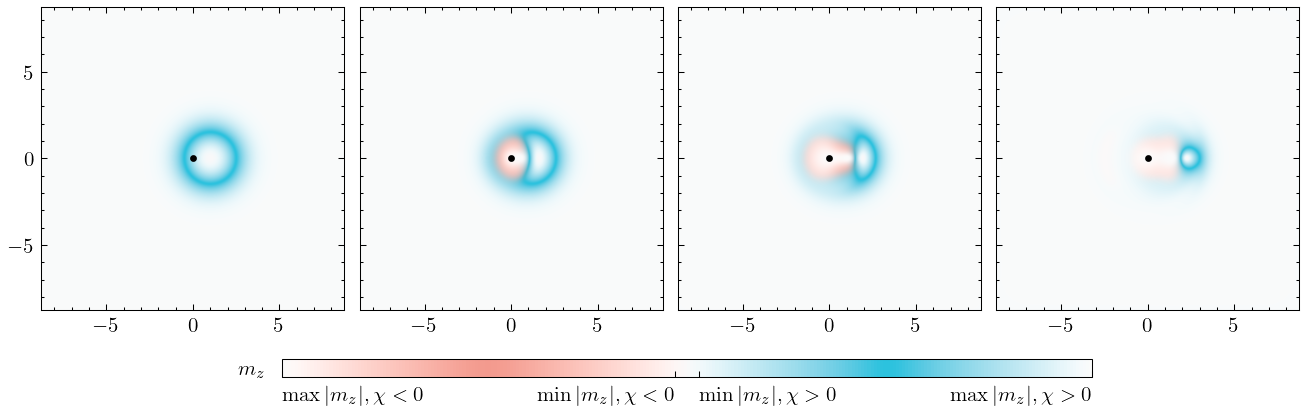

In [51]:
from cmap import Colormap
cmap = Colormap('colorcet:cet_cbtc2').to_mpl()
fig,ax = plt.subplots(1,4, figsize=(9,3), sharey=True)
fig.tight_layout()


mappable = draw_field(ax[0], data[0], mode='chirality', cutoff=50)
draw_field(ax[1], data[2], mode='chirality', cutoff=50)
draw_field(ax[2], data[4], mode='chirality', cutoff=50)
draw_field(ax[3], data[8], mode='chirality', cutoff=50)

cbar_ax = fig.add_axes([0.22, 0.08, 0.6, 0.04])

cbar = plt.colorbar(mappable, cax=cbar_ax, orientation='horizontal')
cbar_ax.set_ylabel('$m_{z}$', rotation=0, va='center', labelpad=15)
cbar.set_ticks([-1, -0.03, 0.03, 1])
cbar.set_ticklabels([
    "$\\max{|m_z|}, \\chi < 0$",
    "$\\min{|m_z|}, \\chi < 0$",
    "$\\min{|m_z|}, \\chi > 0$",
    "$\\max{|m_z|}, \\chi > 0$",
])
# cbar.set_ticks([-1, 0, 1])
for a in ax:
    a.scatter(0, 0, c='black', s=5, marker='o')
for i, tick in enumerate(cbar.long_axis.get_majorticklabels()):
    if (i % 2 == 0):
        tick.set_horizontalalignment('left')
    else:
        tick.set_horizontalalignment('right')
cbar_ax.tick_params(which='minor', length=0)
plt.subplots_adjust(wspace=0.05, hspace=0.05, bottom=0.2)
plt.show()

In [ ]:
file_to_array

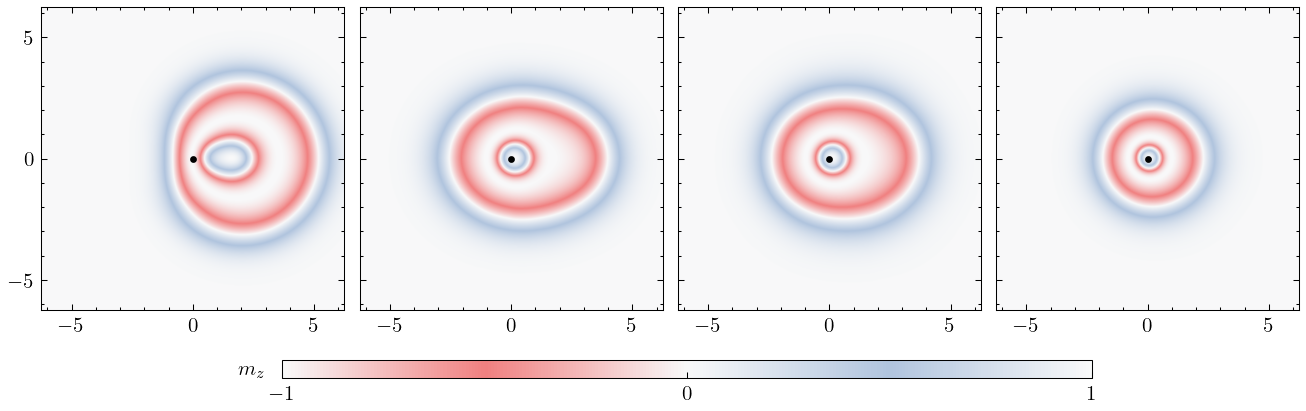

In [119]:
from cmap import Colormap
cmap = Colormap('colorcet:cet_cbtc2').to_mpl()
fig,ax = plt.subplots(1,4, figsize=(9,3), sharey=True)
fig.tight_layout()


mappable = draw_field(ax[0], data[4], mode='m_z', cutoff=150)
draw_field(ax[1], data[26], mode='m_z', cutoff=150)
draw_field(ax[2], data[30], mode='m_z', cutoff=150)
draw_field(ax[3], data[50], mode='m_z', cutoff=150)

cbar_ax = fig.add_axes([0.22, 0.08, 0.6, 0.04])

cbar = plt.colorbar(mappable, cax=cbar_ax, orientation='horizontal')
cbar_ax.set_ylabel('$m_{z}$', rotation=0, va='center', labelpad=15)
# cbar.set_ticks([-1, -0.03, 0.03, 1])
# cbar.set_ticklabels([
#     "$\\max{|m_z|}, \\chi < 0$",
#     "$\\min{|m_z|}, \\chi < 0$",
#     "$\\min{|m_z|}, \\chi > 0$",
#     "$\\max{|m_z|}, \\chi > 0$",
# ])
cbar.set_ticks([-1, 0, 1])
for a in ax:
    a.scatter(0, 0, c='black', s=5, marker='o')
# for i, tick in enumerate(cbar.long_axis.get_majorticklabels()):
#     if (i % 2 == 0):
#         tick.set_horizontalalignment('left')
#     else:
#         tick.set_horizontalalignment('right')
cbar_ax.tick_params(which='minor', length=0)
plt.subplots_adjust(wspace=0.05, hspace=0.05, bottom=0.2)
plt.show()

In [633]:
M = file_to_array('./skyrmion_system/large-skyrmion-alpha=-3,a=0.5/m0.omf')

$$
\Chi = (\mathbf m \cdot \nabla) m_z
$$

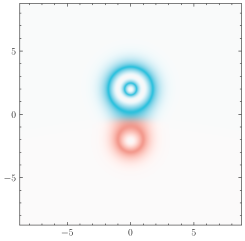

In [23]:
from scripts.mm import Field

field = Field(count=800, center=(0,0), sizeX=10)
distance = 2
M = field.M(lambda r: 4* np.arctan(np.sinh(1) / np.sinh(r)), to=(-distance, 0)).transpose((1,0,2))  + field.M(lambda r: -2* np.arctan(np.sinh(1) / np.sinh(r)), to=(distance, 0), reduce_z=True).transpose((1,0,2))
M = M / np.linalg.norm(M, axis=-1, keepdims=True)
fig, ax = plt.subplots()

draw_field(ax, M, mode='chirality')

### Trying to compute radii

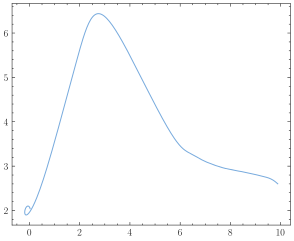

In [362]:
from scipy.interpolate import make_smoothing_spline

distances = []
radii = []
data_slice = np.mean(data[:, 399 - 7:401 + 7, :, :], axis=1)
density = 20 / 800

for i in range(len(data_slice))[10:-10]:
    v = np.argsort(np.abs(data_slice[i,:,-1]))
    left = v[0]
    idx = 1
    right = v[idx]
    while (np.abs(left -right) < 3):
        idx += 1
        right = v[idx]
    radii.append(np.abs(left - right) * density)
    distances.append(((left + right) / 2 - 400) * density + 5)
    
t = np.linspace(0, 1, len(distances))
distance_spline = make_smoothing_spline(t, distances)
radius_spline = make_smoothing_spline(t, radii)
t = np.linspace(0, 1, 1000)
plt.plot(distance_spline(t), radius_spline(t))
plt.show()

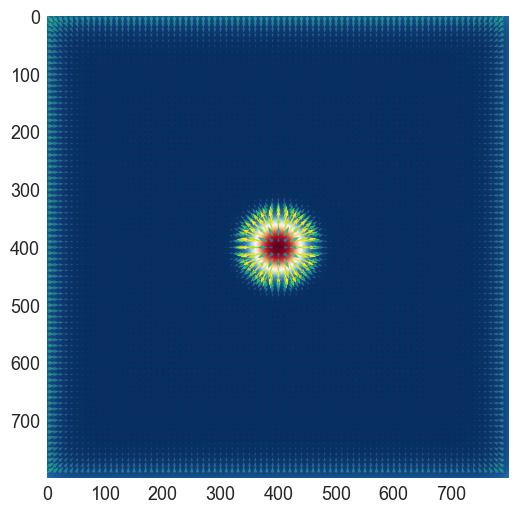

In [99]:
fig, ax = plt.subplots()
ax.imshow(data[-1,:,:,-1], cmap="RdBu")
X, Y = np.meshgrid(np.arange(0, 800, 10), np.arange(0, 800, 10))
U, V = data[-1,Y,X,1], -data[-1,Y,X,0]
ax.quiver(X, Y, U, V, np.hypot(U,V), width=0.003, scale=30)
plt.show()

In [10]:
arr = file_to_array('./skyrmion_system/drive-0/m0.omf')